# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [20]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Смачило Іванна'      # прізвище та ім'я
GROUP        = 'СШІ-33'      # шифр групи, наприклад СШІ-31
NUMBER       = 11       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Смачило Іванна | СШІ-33 | номер 11


In [21]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 11   ·   Смачило Іванна   ·   СШІ-33

   Ринок:  Mykolaiv
   Товар:  масло   (у наборі даних: Butter - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [22]:
# Завдання 1. Підготовка ряду
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (11, 3.8), 'axes.grid': True,
                     'grid.alpha': .25, 'font.family': 'DejaVu Sans'})

prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))

GRID = pd.date_range('2014-03-01', '2017-12-01', freq='MS')

raw = (prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)]
       .set_index('date')['ціна'].sort_index())
assert raw.index.is_unique, 'дублі дат у ряді'

s_raw = raw.reindex(GRID)
gaps  = s_raw[s_raw.isna()].index

print(f'Місяців у сітці:        {len(GRID)}')
print(f'Місяців із виміром:     {s_raw.notna().sum()}')
print(f'Пропущені місяці:       {[d.strftime("%m.%Y") for d in gaps]}')

absent_everywhere = sorted(set(GRID) - set(prices['date']))
print('Місяці, яких немає в жодному рядку всього набору:',
      [d.strftime('%m.%Y') for d in absent_everywhere])
print('Кількість рядів (ринок × товар) у наборі:', prices.groupby(['ринок', 'товар']).ngroups)
print('Рядків за серпень 2017 у всьому наборі:', (prices['date'] == '2017-08-01').sum())

Місяців у сітці:        46
Місяців із виміром:     45
Пропущені місяці:       ['08.2017']
Місяці, яких немає в жодному рядку всього набору: ['08.2017']
Кількість рядів (ринок × товар) у наборі: 700
Рядків за серпень 2017 у всьому наборі: 0


**Висновок до завдання 1:**

1. Повна сітка містить 46 місяців(03.2014 – 12.2017); виміри є у 45 з них.
2. Пропуск — серпень 2017.
3. Це не особливість ринку Mykolaiv чи масла: у всьому наборі немає жодного рядка за серпень 2017(для жодного з 700 рядів «ринок × товар»), тобто дірка виникла на рівні джерела (збір або публікація даних WFP за цей місяць). Причину самого пропуску з файлу встановити не можна — можна лише довести, що вона системна. Тому пропуск у ряді один(так само, як у всіх інших); якби знайшлося більше — це означало б помилку у побудові сітки.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

Сусідні виміри: липень 2017 = 140.3900, вересень 2017 = 145.4533
перенесення останнього (ffill)    140.3900
лінійна інтерполяція              142.9216
pchip (монотонний сплайн)         143.1859
Розкид між способами: 2.80 грн (2.0 % від рівня)


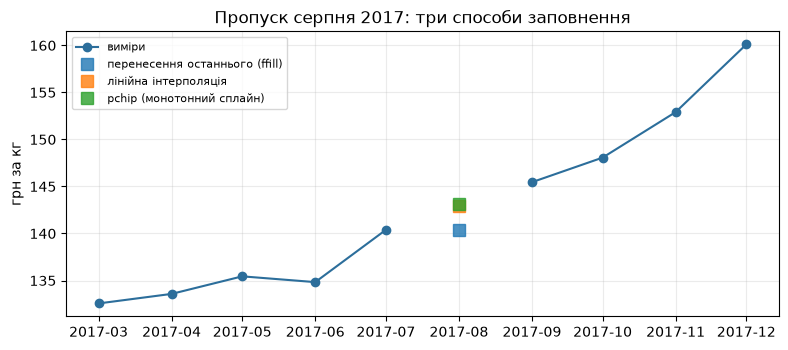


Кількість місяців із даними по ринках (найменші):
ринок
Crimea            1
m. Sevastopol     2
Luhanska         40
Donetska         42
Zhytomyr         45


In [23]:
# Завдання 2. Заповнення пропуску
gap = gaps[0]
filled = {
    'перенесення останнього (ffill)': s_raw.ffill(),
    'лінійна інтерполяція':           s_raw.interpolate('linear'),
    'pchip (монотонний сплайн)':      s_raw.interpolate('pchip'),
}
table = pd.Series({k: v[gap] for k, v in filled.items()})
print('Сусідні виміри: липень 2017 = %.4f, вересень 2017 = %.4f'
      % (s_raw['2017-07-01'], s_raw['2017-09-01']))
print(table.round(4).to_string())
print('Розкид між способами: %.2f грн (%.1f %% від рівня)'
      % (table.max() - table.min(), (table.max() - table.min()) / table.mean() * 100))

CHOSEN = 'лінійна інтерполяція'
s = filled[CHOSEN].rename('price')
assert len(s) == 46 and s.notna().all()

fig, ax = plt.subplots(figsize=(8, 3.6))
w = slice('2017-03-01', '2017-12-01')
ax.plot(s_raw[w].index, s_raw[w].values, 'o-', color='#2C6E9B', label='виміри')
for k, v in filled.items():
    ax.plot(gap, v[gap], 's', ms=9, label=k, alpha=.8)
ax.set_title('Пропуск серпня 2017: три способи заповнення'); ax.set_ylabel('грн за кг')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

cnt = prices.groupby('ринок')['date'].nunique().sort_values()
print('\nКількість місяців із даними по ринках (найменші):')
print(cnt.head(5).to_string())

**Висновок до завдання 2:**

1. Серпень 2017: перенесення останнього — 140,39 грн; лінійна інтерполяція — 142,92 грн; pchip — 143,19 грн. Сусідні виміри: 140,39 (липень) і 145,45 (вересень).
2. Обрано лінійну інтерполяцію. Ряд майже монотонно зростає, тому перенесення останнього значення гарантовано занижує (воно «вигадує» нульовий приріст у місяць, коли сусіди відрізняються на 5 грн). Лінійна — найпростіший спосіб, що враховує нахил між двома сусідніми точками, не дає «переколивань» сплайна і збігається з режимом Linear у віджеті Interpolate в Orange, тож Частина 2 працюватиме на тих самих даних. Розкид між способами лише 2,8 грн (≈2 % рівня), тобто вибір істотно не впливає на висновки.
3. Заповнювати неприпустимо, коли відсутність даних сама є інформацією або дірка довга. У цьому наборі: Crimea має 1 місяць даних, m. Sevastopol — 2(ряди обриваються у 2014 р. через втрату доступу до території); Luhanska(40 міс.) і Donetska(42 міс.) мають системні діри, пов’язані з війною. Інтерполяція там створювала б «дані», яких ніхто не спостерігав. Окреме застереження для нашого ряду: лінійна інтерполяція використовує майбутнє значення(вересень), тому в перевірці з рухомим початком фолд 2(перевіряє 07–09.2017) містить один «факт», який насправді є штучним.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

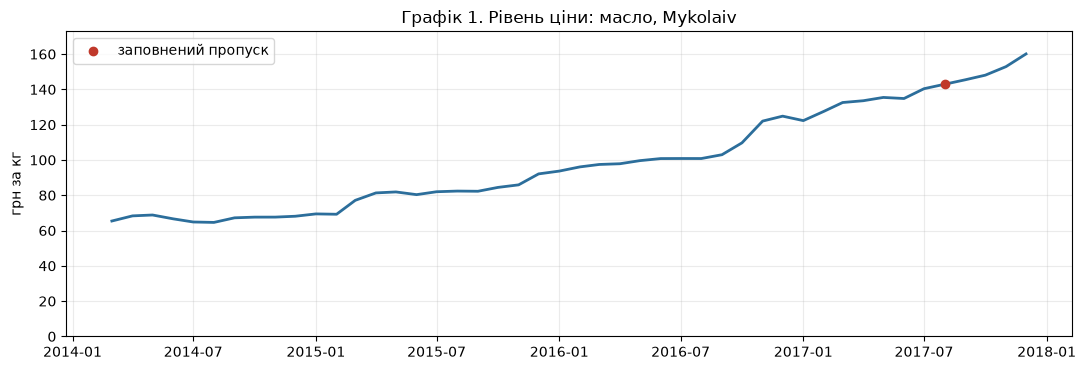

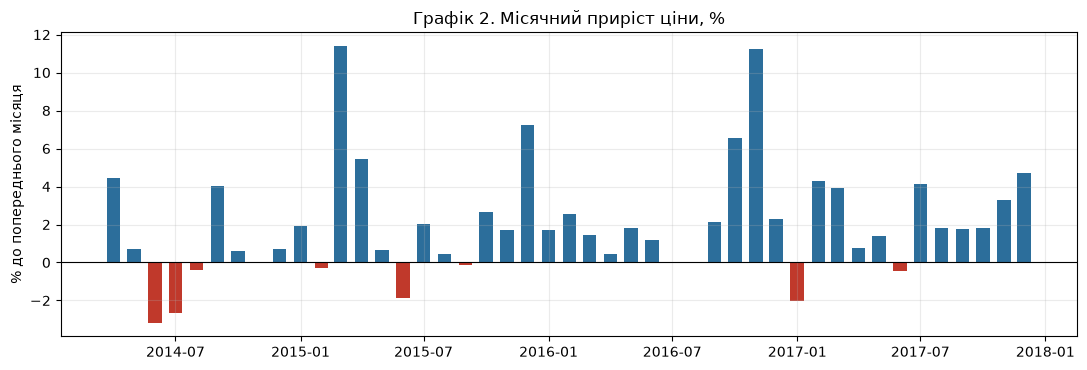

Місяців зі зростанням: 36 із 45; середній приріст 2.05 %/міс
2015-03-01    11.4
2016-11-01    11.2
2015-12-01     7.2


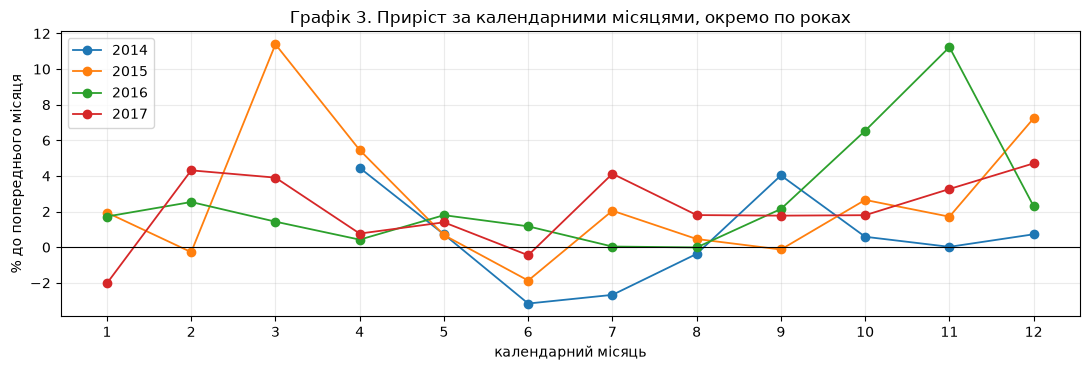

year   2014  2015  2016  2017
month                        
1       NaN   1.9   1.7  -2.0
2       NaN  -0.3   2.5   4.3
3       NaN  11.4   1.4   3.9
4       4.5   5.5   0.4   0.8
5       0.7   0.7   1.8   1.4
6      -3.2  -1.9   1.2  -0.5
7      -2.7   2.0   0.0   4.1
8      -0.4   0.5  -0.0   1.8
9       4.0  -0.1   2.1   1.8
10      0.6   2.7   6.5   1.8
11      0.0   1.7  11.2   3.3
12      0.7   7.2   2.3   4.7


In [24]:
# Завдання 3. Візуальна розвідка
fig, ax = plt.subplots()
ax.plot(s.index, s.values, lw=2, color='#2C6E9B')
ax.scatter([gap], [s[gap]], color='#C0392B', zorder=5, label='заповнений пропуск')
ax.set_ylim(0, s.max() * 1.08); ax.set_ylabel('грн за кг')
ax.set_title(f'Графік 1. Рівень ціни: {GOOD_UA}, {MARKET}'); ax.legend(); plt.tight_layout(); plt.show()

pct = s.pct_change().dropna() * 100
fig, ax = plt.subplots()
ax.bar(pct.index, pct.values, width=20, color=np.where(pct >= 0, '#2C6E9B', '#C0392B'))
ax.axhline(0, color='k', lw=.8); ax.set_ylabel('% до попереднього місяця')
ax.set_title('Графік 2. Місячний приріст ціни, %'); plt.tight_layout(); plt.show()
print('Місяців зі зростанням: %d із %d; середній приріст %.2f %%/міс'
      % ((pct > 0).sum(), len(pct), pct.mean()))
print(pct.nlargest(3).round(1).to_string())

df = pct.to_frame('p'); df['year'] = df.index.year; df['month'] = df.index.month
fig, ax = plt.subplots()
for yr, g in df.groupby('year'):
    ax.plot(g['month'], g['p'], 'o-', lw=1.3, label=str(yr))
ax.axhline(0, color='k', lw=.8); ax.set_xticks(range(1, 13))
ax.set_xlabel('календарний місяць'); ax.set_ylabel('% до попереднього місяця')
ax.set_title('Графік 3. Приріст за календарними місяцями, окремо по роках'); ax.legend()
plt.tight_layout(); plt.show()
print(df.pivot(index='month', columns='year', values='p').round(1))

**Висновок до завдання 3:**

**Графік 1(лінія, лінійна шкала від нуля).** Питання: яким був рівень і траєкторія ціни? Лінія — бо точки впорядковані в часі й важлива неперервність; шкала від нуля — бо рівень порівнюється як величина. Ціна зросла з 65,40 до 160,10 грн, тобто в 2,45 раза.

**Графік 2(стовпці місячного приросту, %).** Питання: коли саме відбувалося зростання — рівномірно чи стрибками? Стовпці від нульової лінії, бо величина — відхилення від нуля; колір розділяє зростання й падіння. Відносна зміна, а не гривні, бо рівень сильно змінюється (65 → 160), і гривневі прирости у 2014 і 2017 роках були б несумісні.

**Графік 3(приріст за календарними місяцями, лінія на кожен рік).** Питання: чи повторюється картина в ті самі місяці? Використано прирости, а не рівні: тренд прибрано диференціюванням, тому він не імітує сезонність. Лінії по роках дозволяють порівняти один і той самий місяць між роками.

**Несподівана знахідка.** Зростання не плавне: із 45 місячних змін 36 додатних(середній приріст ≈2,05 %/міс), але два місяці дають стрибок понад 11 %: березень 2015(+11,4 %) і листопад 2016 (+11,2 %), а також грудень 2015 (+7,2 %). Березневий стрибок 2015 р. у наступні роки не повторюється (березень 2016: +1,4 %, 2017: +3,9 %), тобто це схоже на разовий шок, а не на сезон. Червень у трьох роках із чотирьох від’ємний (−3,2; −1,9; −0,5 %; 2016 — +1,2 %).

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

In [25]:
import sys
!{sys.executable} -m pip install statsmodels


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


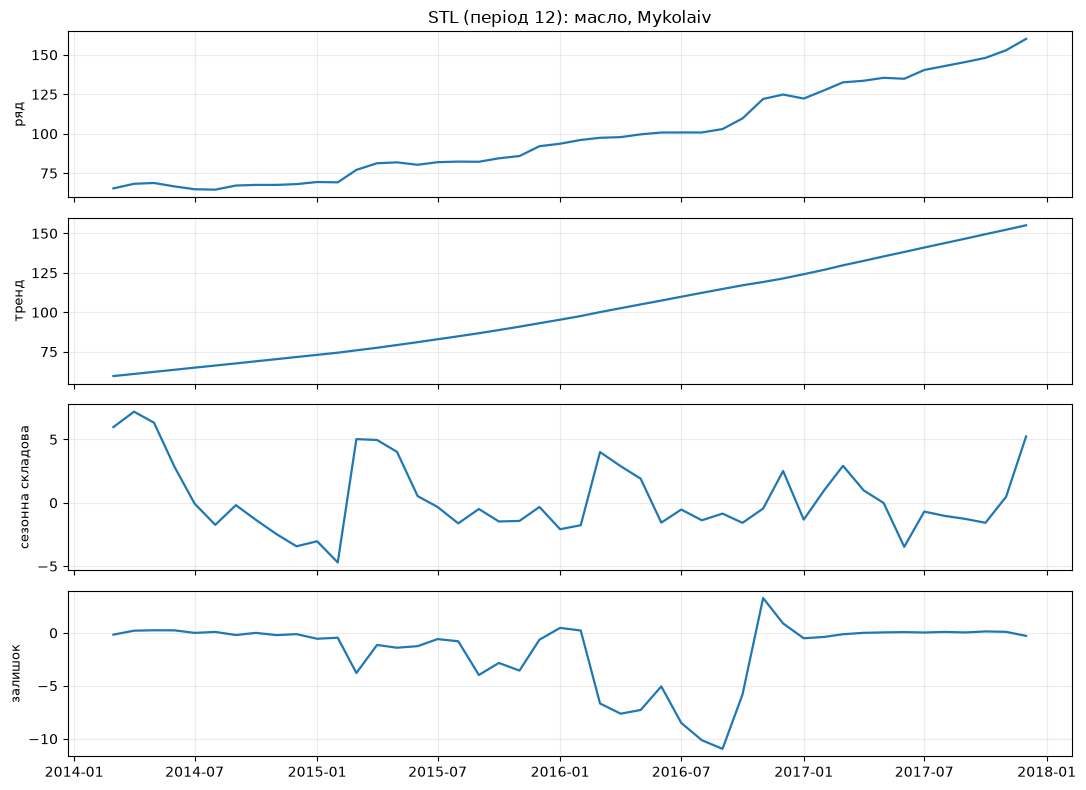

F_S (сила сезонності) = 0.446
F_T (сила тренду)     = 0.988
Амплітуда сезонної складової: 11.89 грн (розмах)
=> СЕЗОННІСТЬ Є (F_S >= 0.3)


In [26]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL

res = STL(s, period=12, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, d, t in zip(axes, [s, res.trend, res.seasonal, res.resid],
                    ['ряд', 'тренд', 'сезонна складова', 'залишок']):
    ax.plot(d.index, d.values, lw=1.6); ax.set_ylabel(t, fontsize=9)
axes[0].set_title(f'STL (період 12): {GOOD_UA}, {MARKET}')
plt.tight_layout(); plt.show()

FS = max(0, 1 - np.var(res.resid) / np.var(res.seasonal + res.resid))
FT = max(0, 1 - np.var(res.resid) / np.var(res.trend + res.resid))
print('F_S (сила сезонності) = %.3f' % FS)
print('F_T (сила тренду)     = %.3f' % FT)
print('Амплітуда сезонної складової: %.2f грн (розмах)' % (res.seasonal.max() - res.seasonal.min()))
print('=> СЕЗОННІСТЬ Є (F_S >= 0.3)' if FS >= 0.3 else '=> СЕЗОННОСТІ ФАКТИЧНО НЕМАЄ (F_S < 0.3)')

**Висновок до завдання 4:**

STL із періодом 12 розклав ряд на тренд, сезонну складову та залишок. Сила сезонності F_S = 0,446, сила тренду F_T = 0,988. Розмах сезонної складової становить 11,89 грн.

Сезонність у ряді є, бо F_S перевищує поріг 0,3. Вона помірна: на залишок припадає понад половина дисперсії (1 − 0,446 ≈ 0,55). Динаміку ціни майже повністю визначає тренд (×2,45). Сезонна складова нестійка, її піки різні за величиною. У ряді лише ≈3,8 цикла по 12 місяців, тому оцінка F_S ненадійна.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

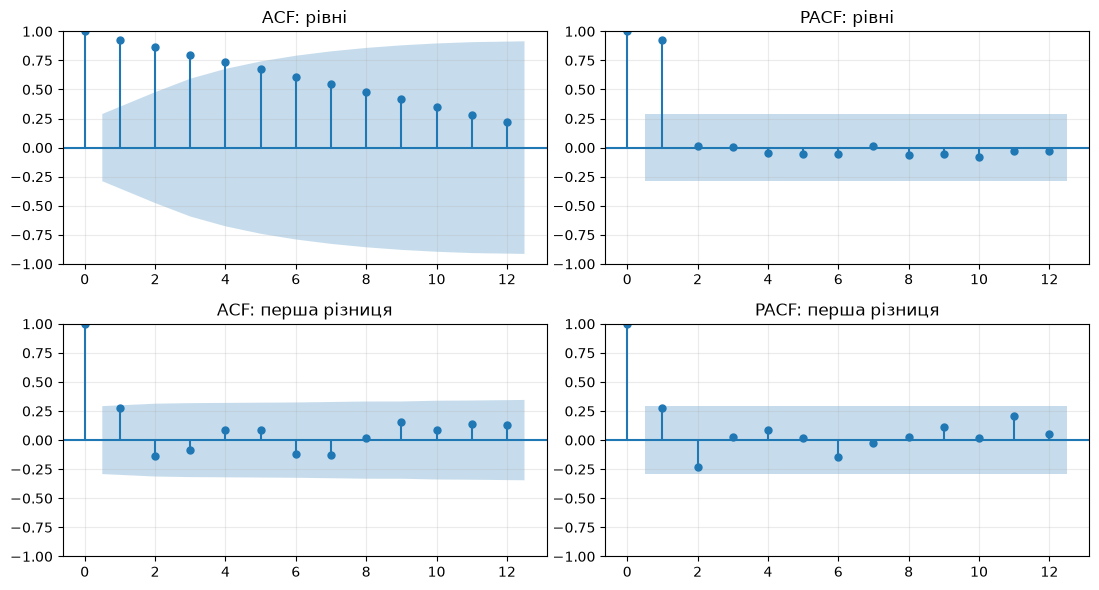

          ряд  ADF p       ADF каже  KPSS p      KPSS каже  тести узгоджені
        рівні 0.9989 НЕстаціонарний  0.0100 НЕстаціонарний             True
перша різниця 0.0001   стаціонарний  0.0197 НЕстаціонарний            False


In [27]:
# Завдання 5. Стаціонарність
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

d1 = s.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
plot_acf (s,  lags=12, ax=axes[0, 0], title='ACF: рівні')
plot_pacf(s,  lags=12, ax=axes[0, 1], title='PACF: рівні', method='ywm')
plot_acf (d1, lags=12, ax=axes[1, 0], title='ACF: перша різниця')
plot_pacf(d1, lags=12, ax=axes[1, 1], title='PACF: перша різниця', method='ywm')
plt.tight_layout(); plt.show()

rows = []
for name, x in [('рівні', s), ('перша різниця', d1)]:
    p_adf  = adfuller(x, autolag='AIC')[1]
    p_kpss = kpss(x, regression='c', nlags='auto')[1]
    adf_stat  = p_adf < 0.05
    kpss_stat = p_kpss > 0.05
    rows.append({'ряд': name, 'ADF p': round(p_adf, 4), 'ADF каже': 'стаціонарний' if adf_stat else 'НЕстаціонарний',
                 'KPSS p': round(p_kpss, 4), 'KPSS каже': 'стаціонарний' if kpss_stat else 'НЕстаціонарний',
                 'тести узгоджені': adf_stat == kpss_stat})
print(pd.DataFrame(rows).to_string(index=False))

**Висновок до завдання 5:**

ADF і KPSS узгоджуються для рівнів і не узгоджуються для першої різниці.

| Ряд | ADF p | KPSS p | Висновок |
|---|---|---|---|
| рівні | 0,9989 | 0,0100 | обидва: нестаціонарний |
| перша різниця | 0,0001 | 0,0197 | ADF: стаціонарний, KPSS: нестаціонарний |

Рівні нестаціонарні: ADF не відхиляє нульову гіпотезу про нестаціонарність (p ≈ 1), KPSS її відхиляє; ACF повільно спадає (0,93 → 0,60 на лагу 6, значущі лаги 1–10). Для першої різниці ADF каже «стаціонарна», а KPSS (p = 0,0197) ледь відхиляє стаціонарність, і значущих лагів ACF немає (найбільший 0,27 при межі ±0,29). Ймовірне пояснення: прирости ціни не сталі, у 2014 році вони близько 0,3 грн/міс, а у 2017 — кілька гривень, і є разові стрибки. KPSS чутливий до такої зміни середнього. Практичний висновок: потрібне одне диференціювання (d = 1), друге було б надмірним.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [28]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
H, F = 3, 7
y = s.values.astype(float); N = len(y)

def fc_naive (tr, h): return np.repeat(tr[-1], h)
def fc_snaive(tr, h): return np.array([tr[len(tr) - 12 + (k % 12)] for k in range(h)])
def fc_mean  (tr, h): return np.repeat(tr.mean(), h)
def fc_drift (tr, h): return tr[-1] + np.arange(1, h + 1) * (tr[-1] - tr[0]) / (len(tr) - 1)
BASES = {'наївний': fc_naive, 'сезонний наївний': fc_snaive, 'середнє': fc_mean, 'дрейф': fc_drift}

def rolling_origin(y, fc_fn, h=H, folds=F):
    """Фолд f: навчання — усе до позиції -h*f, перевірка — наступні h. Порядок: f = 7 … 1 (за часом)."""
    act, pred = [], []
    for f in range(folds, 0, -1):
        end = len(y) - h * f
        act.append(y[end:end + h]); pred.append(np.asarray(fc_fn(y[:end], h)))
    return np.concatenate(act), np.concatenate(pred)

def metrics(a, p):
    e = a - p
    return {'MAE': np.mean(np.abs(e)), 'RMSE': np.sqrt(np.mean(e ** 2)),
            'MAPE, %': np.mean(np.abs(e / a)) * 100}

tab = pd.DataFrame({k: metrics(*rolling_origin(y, fn)) for k, fn in BASES.items()}).T
print('Перевірені місяці:', s.index[-21].strftime('%m.%Y'), '–', s.index[-1].strftime('%m.%Y'))
print(tab.round(3).to_string())
BEST = tab['MAE'].idxmin(); print('\nНайкращий базис за MAE:', BEST)

def random_split_mae(name, seed):
    r = np.random.default_rng(seed); idx = np.arange(N); r.shuffle(idx)
    ntr = int(round(.75 * N)); tr = np.sort(idx[:ntr]); te = np.sort(idx[ntr:]); err = []
    for t in te:
        if name == 'наївний':
            j = tr[tr < t]; f = y[j[-1]] if len(j) else y[tr[0]]
        elif name == 'сезонний наївний':
            j = tr[tr <= t - 12]; f = y[j[-1]] if len(j) else y[tr[0]]
        elif name == 'середнє':
            f = y[tr].mean()
        else:
            j = tr[tr < t]
            f = y[j[-1]] + (t - j[-1]) * (y[j[-1]] - y[j[0]]) / (j[-1] - j[0]) if len(j) > 1 else y[tr[0]]
        err.append(abs(y[t] - f))
    return np.mean(err)

cmp = pd.DataFrame({'MAE рухомий початок': tab['MAE'],
                    'MAE випадковий 75/25': {k: np.mean([random_split_mae(k, sd) for sd in range(200)]) for k in BASES}})
cmp['рухомий / випадковий'] = cmp.iloc[:, 0] / cmp.iloc[:, 1]
print('\n', cmp.round(3).to_string())

Перевірені місяці: 04.2016 – 12.2017
                     MAE    RMSE  MAPE, %
наївний            5.904   8.399    4.509
сезонний наївний  30.301  31.411   23.759
середнє           40.059  42.205   31.005
дрейф              4.155   6.318    3.254

Найкращий базис за MAE: дрейф

                   MAE рухомий початок  MAE випадковий 75/25  рухомий / випадковий
наївний                         5.904                 3.143                 1.878
сезонний наївний               30.301                19.701                 1.538
середнє                        40.059                24.387                 1.643
дрейф                           4.155                 2.475                 1.679


**Висновок до завдання 6:**

Перевірка з рухомим початком (7 фолдів по 3 кроки, останні 21 місяць, усі фолди разом):

| Базис | MAE | RMSE | MAPE, % |
|---|---|---|---|
| наївний | 5,904 | 8,399 | 4,51 |
| сезонний наївний | 30,301 | 31,411 | 23,76 |
| середнє | 40,059 | 42,205 | 31,01 |
| **дрейф** | **4,155** | **6,318** | **3,25** |

Найкращий базис — дрейф: ряд майже монотонно зростає (в 2,45 раза), тож найкраще працює продовження середнього нахилу. Середнє відстає від рівня, що росте, а сезонний наївний бере ціну річної давності, яка на 25–40 % нижча.

Випадковий поділ 75/25 дає помилку в 1,5–1,9 раза меншу (наївний 3,14 проти 5,90; дрейф 2,48 проти 4,16). Така оцінка занадто оптимістична для прогнозування: тестові місяці оточені навчальними, а вибірка охоплює спокійний 2014 рік. Рухомий початок перевіряє лише найдинамічніші останні 21 місяць.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

                     MAE    RMSE  MAPE, %
наївний            5.904   8.399    4.509
сезонний наївний  30.301  31.411   23.759
середнє           40.059  42.205   31.005
дрейф              4.155   6.318    3.254
ARIMA(1,1,1)       5.281   7.848    4.024

Найкращий базис: дрейф | MAE базису = 4.155, MAE ARIMA = 5.281 -> ARIMA ПРОГРАЄ базису
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4153      0.319      1.303      0.192      -0.209       1.040
ma.L1          0.1700      0.371      0.458      0.647      -0.557       0.897
sigma2         9.1466      1.623      5.637      0.000       5.966      12.327


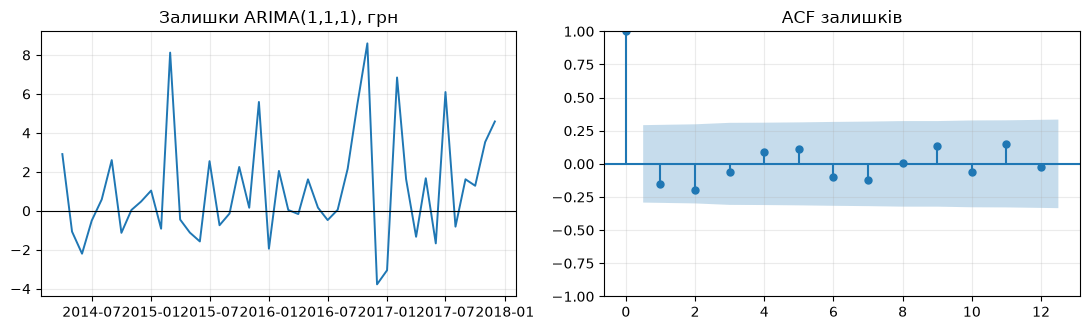

     lb_stat  lb_pvalue
6   4.822951   0.566714
12  8.296639   0.761541


In [29]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

def fc_arima(tr, h): return ARIMA(tr, order=(1, 1, 1)).fit().forecast(h)

A_act, A_pred = rolling_origin(y, fc_arima)
m_arima = metrics(A_act, A_pred)

cmp7 = tab.copy(); cmp7.loc['ARIMA(1,1,1)'] = pd.Series(m_arima)
print(cmp7.round(3).to_string())
print('\nНайкращий базис:', BEST, '| MAE базису = %.3f, MAE ARIMA = %.3f -> ARIMA %s'
      % (tab.loc[BEST, 'MAE'], m_arima['MAE'],
         'виграє' if m_arima['MAE'] < tab.loc[BEST, 'MAE'] else 'ПРОГРАЄ базису'))

full = ARIMA(y, order=(1, 1, 1)).fit()
print(full.summary().tables[1])
resid = full.resid[1:]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(s.index[1:], resid, lw=1.4); axes[0].axhline(0, color='k', lw=.8)
axes[0].set_title('Залишки ARIMA(1,1,1), грн')
plot_acf(resid, lags=12, ax=axes[1], title='ACF залишків'); plt.tight_layout(); plt.show()
print(acorr_ljungbox(resid, lags=[6, 12]))

**Висновок до завдання 7:**

ARIMA(1,1,1) на тих самих 7 фолдах: MAE = 5,281; RMSE = 7,848; MAPE = 4,02 %.

Порядок за ACF/PACF: після першої різниці жоден лаг ACF не значущий (лаг 1 дорівнює 0,27 при межі ±0,29), тож авторегресійної чи ковзної структури не видно. Обрав би (0,1,0) із сталою, тобто випадкове блукання зі зсувом.

Порівняння: найкращий базис дрейф має MAE 4,155, тобто ARIMA гірша приблизно на 27 %. Від наївного (5,904) вона кращою лише на ≈11 %. Обидва коефіцієнти статистично незначущі (AR 0,42, p = 0,19; MA 0,17, p = 0,65), отже модель по суті є наївним прогнозом без зсуву. Висновок: ARIMA(1,1,1) не має права на існування, бо програє простому дрейфу. Це законний результат: у statsmodels за d = 1 константа не включається, тому модель не бачить стабільного зростання, яке дрейф враховує.

Залишки: тест Льюнга–Бокса дає p = 0,57 (лаг 6) і p = 0,76 (лаг 12), тож автокореляції в залишках не лишилося.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Скан по рівнях: дата 11.2016, t = 13.83, середнє до = 82.41, після = 137.36


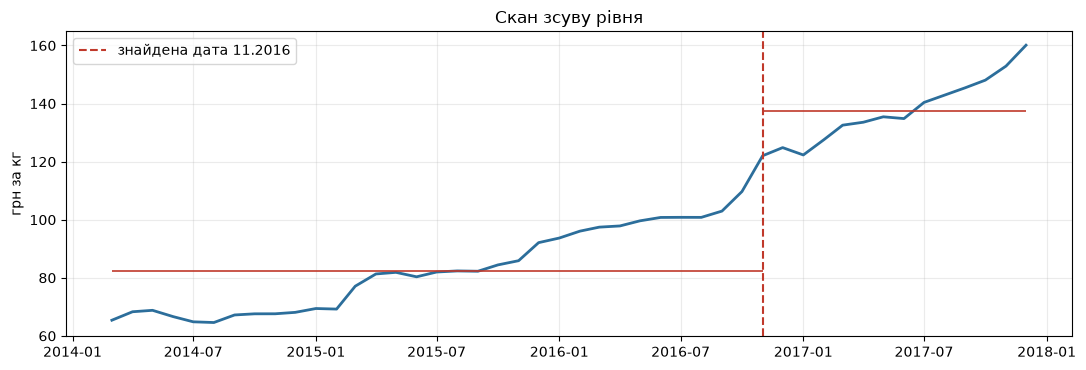

Скан по логприростах: дата 03.2015, t = 2.25, середній приріст до = 0.52 %/міс, після = 2.47 %/міс
Пермутаційне p-значення для max|t| (врахування сканування): 0.284
95% поріг max|t| під H0: 3.11


In [30]:
# Завдання 8. Точка зміни режиму
from scipy import stats

def scan(x, minseg=6):
    """Для кожної дати-кандидата — t-статистика Уелча (середнє після vs до); беремо max |t|."""
    out = []
    for k in range(minseg, len(x) - minseg + 1):
        out.append((k, stats.ttest_ind(x[k:], x[:k], equal_var=False).statistic))
    return max(out, key=lambda z: abs(z[1]))

k, tval = scan(y)
cp = s.index[k]
print('Скан по рівнях: дата %s, t = %.2f, середнє до = %.2f, після = %.2f'
      % (cp.strftime('%m.%Y'), tval, y[:k].mean(), y[k:].mean()))

fig, ax = plt.subplots()
ax.plot(s.index, s.values, lw=2, color='#2C6E9B')
ax.axvline(cp, color='#C0392B', ls='--', label=f'знайдена дата {cp:%m.%Y}')
ax.hlines([y[:k].mean(), y[k:].mean()], [s.index[0], cp], [cp, s.index[-1]], colors='#C0392B', lw=1.2)
ax.set_title('Скан зсуву рівня'); ax.set_ylabel('грн за кг'); ax.legend(); plt.tight_layout(); plt.show()

d = np.diff(np.log(y)); k2, t2 = scan(d); cp2 = s.index[1:][k2]
rng = np.random.default_rng(0)
def max_abs_t(x, minseg=6):
    return max(abs(stats.ttest_ind(x[j:], x[:j], equal_var=False).statistic) for j in range(minseg, len(x) - minseg + 1))
perm = np.array([max_abs_t(rng.permutation(d)) for _ in range(2000)])
print('Скан по логприростах: дата %s, t = %.2f, середній приріст до = %.2f %%/міс, після = %.2f %%/міс'
      % (cp2.strftime('%m.%Y'), t2, d[:k2].mean() * 100, d[k2:].mean() * 100))
print('Пермутаційне p-значення для max|t| (врахування сканування): %.3f' % np.mean(perm >= abs(t2)))
print('95%% поріг max|t| під H0: %.2f' % np.quantile(perm, .95))

**Висновок до завдання 8:**

1. Графік із позначеною датою виводиться клітинкою.
2. Скан по рівнях (як вимагає завдання): найбільша |t| — листопад 2016, t = 13,83, середній рівень до = 82,41 грн, після = 137,36 грн.
3. Чи значуща точка? Ні, і сама ця t-статистика нічого не доводить: ряд має тренд (×2,45) і сильну автокореляцію, тому будь-яка дата посередині ряду дасть величезну t — ми порівнюємо не «режими», а ранню й пізню частини одного зростання, а t-тест припускає незалежні спостереження. Крім того, максимум по ~29 кандидатах завищує значущість. Коректніше сканувати логарифмічні прирости(тренд прибрано): найкраща дата — березень 2015, t = 2,25, середній приріст 0,52 %/міс до і 2,47 %/міс після. Пермутаційне p-значення, що враховує сканування (2000 перестановок), дорівнює ≈0,28(95 % поріг max|t| ≈ 3,11, наше 2,25 його не перевищує). Отже, статистично значущої точки зміни режиму в ряді немає.
4. Відмінність від сезонного сплеску. Сезонний сплеск повторюється в ті самі місяці щороку; стрибок березня 2015 (+11,4 %) не повторився (березень 2016 +1,4 %, 2017 +3,9 %) — це разовий шок. Листопад 2016 (+11,2 %) теж разовий за величиною, хоч осіннє прискорення жовтня–грудня простежується щороку (грудень 2015 +7,2 %; жовтень–листопад 2016 +6,5 і +11,2 %; грудень 2017 +4,7 %) — цю частину слід зіставити з F_S із завдання 4. Зовнішнє пояснення стрибка березня 2015 — гіпотеза про відкладений вплив різкої девальвації гривні на початку 2015 року; у наборі даних курсу немає, тож це слід перевірити за даними НБУ.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [31]:
# Завдання 9. Рецензія на чужий аналіз
buck = (prices[(prices['ринок'] == 'Vinnytsia') & (prices['товар'] == 'Buckwheat grits - Retail')]
        .set_index('date')['ціна'].sort_index())
beef = (prices[(prices['ринок'] == 'Vinnytsia') & (prices['товар'] == 'Meat (beef) - Retail')]
        .set_index('date')['ціна'].sort_index())
lviv = (prices[(prices['ринок'] == 'Lviv') & (prices['товар'] == 'Buckwheat grits - Retail')]
        .set_index('date')['ціна'].sort_index())

print('Спостережень:', len(buck), '| місяців у сітці:', len(GRID), '| пропущено на сітці:', buck.reindex(GRID).isna().sum())

for name, x in [('гречка', buck), ('яловичина', beef)]:
    e = (x - x.shift(1)).dropna().abs().mean()
    print('%-10s MAE = %.2f грн | середній рівень = %.1f грн | MAE/рівень = %.1f %%' % (name, e, x.mean(), e / x.mean() * 100))

print('кореляція рівнів Вінниця–Львів: %.3f | кореляція перших різниць: %.3f'
      % (buck.corr(lviv), buck.diff().corr(lviv.diff())))

z = (buck - buck.mean()) / buck.std()
print('|z| > 1.3: %d міс.; |z| > 2: %d міс.; перші з них: %s'
      % ((z.abs() > 1.3).sum(), (z.abs() > 2).sum(), list(buck[z.abs() > 1.3].index.strftime('%m.%y'))[:9]))

w = buck['2016-01':'2016-06']
print('стовпці з ylim від %.2f: реальне зростання січень→червень 2016 = %.1f %%' % (w.min() * .995, (w.max() / w.min() - 1) * 100))

b = buck.reindex(GRID).interpolate('linear').values.astype(float)
for nm, fn in [('наївний', fc_naive), ('дрейф', fc_drift)]:
    a, p = rolling_origin(b, fn)
    print('рухомий початок, %-8s: ' % nm, {k: round(v, 3) for k, v in metrics(a, p).items()})

Спостережень: 45 | місяців у сітці: 46 | пропущено на сітці: 1
гречка     MAE = 1.38 грн | середній рівень = 21.3 грн | MAE/рівень = 6.5 %
яловичина  MAE = 1.51 грн | середній рівень = 78.5 грн | MAE/рівень = 1.9 %
кореляція рівнів Вінниця–Львів: 0.996 | кореляція перших різниць: 0.936
|z| > 1.3: 12 міс.; |z| > 2: 0 міс.; перші з них: ['03.14', '04.14', '05.14', '06.14', '07.14', '08.14', '09.14', '10.14', '11.14']
стовпці з ylim від 24.76: реальне зростання січень→червень 2016 = 40.6 %
рухомий початок, наївний :  {'MAE': np.float64(2.551), 'RMSE': np.float64(3.205), 'MAPE, %': np.float64(10.107)}
рухомий початок, дрейф   :  {'MAE': np.float64(2.941), 'RMSE': np.float64(3.799), 'MAPE, %': np.float64(12.005)}


**Висновок до завдання 9:**

Нумерація клітинок — за порядком у файлі `ЛР4_помилковий_аналіз.ipynb` (з нуля). Числа нижче перевірені клітинкою завдання.

| № | Клітинка | Помилка | Чим небезпечна |
|---|---|---|---|
| 1 | 1 | `grid` створено, але ніде не використано; `warnings.filterwarnings('ignore')` приховує всі попередження | Ряд не приводиться до сітки; приховані попередження statsmodels (збіжність, interpolation) |
| 2 | 3 | «Пропусків немає» — перевірено `isna()` на ряді без `reindex` на сітку. На сітці 46 місяців є 45 значень (бракує 08.2017) | Нерівна сітка зсуває `shift(12)`, період STL, ACF і ARIMA: лаги означають не те, що здається |
| 3 | 5 | Порівняння першого й останнього значення (×2,47) у номінальних цінах; висновок про «зниження купівельної спроможності» без інфляції/доходів. У підсумку — «у кілька разів», тоді як фактично ×2,47 | Дві точки визначають усе; номінальне зростання не є реальним; причинний висновок без даних |
| 4 | 7 | MAE у гривнях порівнюють для товарів різного рівня цін. MAE 1,38 (гречка) проти 1,51 грн (яловичина), але відносно рівня — **6,5 % проти 1,9 %**, тобто висновок протилежний. Різниця «зараз − місяць тому» — не прогноз з навчанням | Масштабно-залежна метрика дає хибне порівняння; потрібні MAPE/MASE |
| 5 | 9 | Кореляція двох **трендових** рядів (r = 0,996) і висновок «Львів визначає Вінницю» | Хибна кореляція нестаціонарних рядів; кореляція ≠ причинність; на різницях r = 0,94 — високий через спільні шоки (курс, інфляція), але це не доводить впливу |
| 6 | 11 | STL повертає сезонну складову завжди; F_S не обчислено, висновок «отже ряд сезонний»; період 12 застосовано до ряду з пропуском | Шум видається за сезонність, на ньому будуються «сезонні моделі» |
| 7 | 13 | ADF: p > 0,05 — H₀ про нестаціонарність **не відхиляється**, а написано «стаціонарний». Тест KPSS не застосовано. Далі «для надійності» береться **друга** різниця | Протилежний висновок про властивість ряду; перерізнична модель — лаг-1 автокореляція d₂ близько −0,5 — типовий симптом |
| 8 | 15 | Поріг 1,3σ при заявленому «двох σ» (при 2σ аномалій **0**); пошук у вихідному ряді з трендом: 12 «аномалій», з них 9 — перші місяці 2014 | Це не аномалії, а низький початок тренду; аномалії шукають у залишках після зняття тренду й сезонності |
| 9 | 17 | `train_test_split` з перемішуванням на часовому ряді; ARIMA навчається на розрізненій підвибірці; **`np.sort(y_te)`** порівнюється з прогнозом | Витік майбутнього; послідовність у часі зламано; після сортування пари «факт–прогноз» не відповідають датам — помилка штучно занижується |
| 10 | 17 | Порівняння з сезонним наївним — на іншій вибірці й іншому горизонті (1-крокова помилка на всьому ряді); немає ретроспективної перевірки; «висока точність» без масштабу й базису | Порівнюються непорівнянні числа; прогноз без чесного базису |
| 11 | 19 | Прогноз на 12 місяців будує **ARIMA(2,2,1)** — не ту модель, яку «перевіряли» ((1,1,1)), і не обґрунтовану; d = 2 дає квадратичну екстраполяцію; немає інтервалів, горизонт не валідований | Неперевірена модель; «ціна зростатиме» — тривіальна екстраполяція тренду |
| 12 | 21 | Стовпчики з обрізаною віссю (`ylim` від 0,995·min): висоти не пропорційні значенням; «стрімке зростання» без цифри | Реальне зростання січень→червень 2016 — 40,6 %, але візуально виглядає у рази; для стовпців нульова база обов’язкова |
| 13 | 22 | Підсумкові висновки закріплюють помилки 5–10: «стаціонарний», «визначають», «висока точність» | Хибні твердження потрапляють до звіту |

**Як виправити три найсерйозніші.**

1. Кл. 17 (оцінка якості). Замінити випадковий поділ на ретроспективну перевірку з рухомим початком (7 фолдів по 3 кроки, навчання до позиції −3·f), не сортувати `y_te`, порівнювати моделі за MAE/RMSE/MAPE на всіх фолдах разом і обов’язково з наївним/дрейфовим базисом(див. `rolling_origin` у завданні 6; фрагмент у клітинці завдання: на ряді колеги наївний MAE = 2,55 грн, дрейф — 2,94 грн).
2. Кл. 13 (стаціонарність). Прочитати тест правильно: p > 0,05 ⇒ нестаціонарний; додати KPSS; обрати d = 1, перевірити ADF/KPSS на першій різниці; другу різницю не брати, якщо перша вже стаціонарна (контроль: ACF d₂ на лагу 1 має бути не близьким до −0,5).
3. Кл. 9 (кореляція). Досліджувати зв’язок на першій різниці або приростах %, а не на рівнях; формулювати «пов’язані», а не «визначають», і лише за наявності зовнішнього механізму/тестів причинності.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [32]:
# Завдання 10. Експорт ряду для Orange
export = pd.DataFrame({'date': s.index.strftime('%Y-%m-%d'), 'price': s.values})
export.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

chk = pd.read_csv('ряд_для_orange.csv')
print(chk.head(3).to_string(index=False)); print('...')
print('Рядків даних:', len(chk), '| порожніх значень:', int(chk.isna().sum().sum()))
print('Стовпці:', list(chk.columns), '| дата серпня 2017:', chk.loc[chk['date'] == '2017-08-01', 'price'].item())
assert len(chk) == 46 and chk.isna().sum().sum() == 0 and list(chk.columns) == ['date', 'price']
assert chk['date'].str.fullmatch(r'\d{4}-\d{2}-01').all()

      date   price
2014-03-01 65.3967
2014-04-01 68.3100
2014-05-01 68.8033
...
Рядків даних: 46 | порожніх значень: 0
Стовпці: ['date', 'price'] | дата серпня 2017: 142.92165


**Висновок до завдання 10:**

Файл `ряд_для_orange.csv` збережено: 46 рядків даних і заголовок, стовпці `date` (РРРР-ММ-01) та `price`, порожніх значень немає, кодування UTF-8, роздільник — кома. Серпень 2017 заповнено лінійною інтерполяцією: 142,92165. Клітинка перевіряє це асертами.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

In [33]:
# Завдання 11. Потік опрацювання даних
chk = pd.read_csv('ряд_для_orange.csv')
print(chk.dtypes.to_string())
print('date -> формат РРРР-ММ-ДД, Orange розпізнає як time:', chk['date'].str.fullmatch(r'\d{4}-\d{2}-\d{2}').all())
print('Перший вимір: %s, %.4f | останній: %s, %.4f' % (chk['date'].iloc[0], chk['price'].iloc[0], chk['date'].iloc[-1], chk['price'].iloc[-1]))
print('Серпень 2017 (після Interpolate у Orange має збігтися): %.5f' % s['2017-08-01'])

date         str
price    float64
date -> формат РРРР-ММ-ДД, Orange розпізнає як time: True
Перший вимір: 2014-03-01, 65.3967 | останній: 2017-12-01, 160.1000
Серпень 2017 (після Interpolate у Orange має збігтися): 142.92165


**Висновок до завдання 11:**

Файл `ряд_для_orange.csv` має формат `date` (РРРР-ММ-ДД) і `price`; перевірка в Python підтвердила тип `price` числовий, а дати у форматі, який Orange розпізнає як time. Контрольні значення для зіставлення з Orange: перший вимір 2014-03-01 = 65,3967; останній 2017-12-01 = 160,1000; серпень 2017 після Interpolate (Linear) має бути 142,92165.

Потік `File → Form Timeseries → Interpolate → Line Chart` побудовано; `date` розпізнано як datetime, `price` — як numeric.

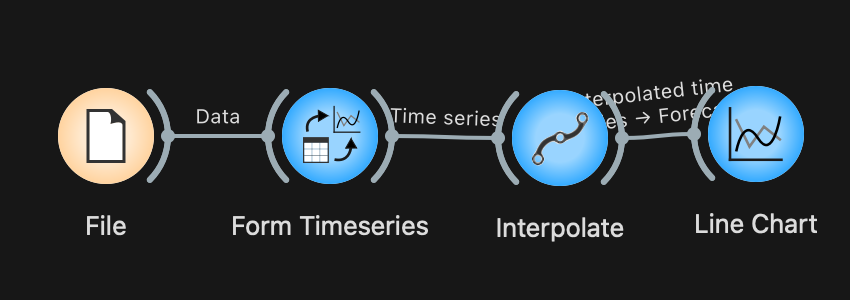

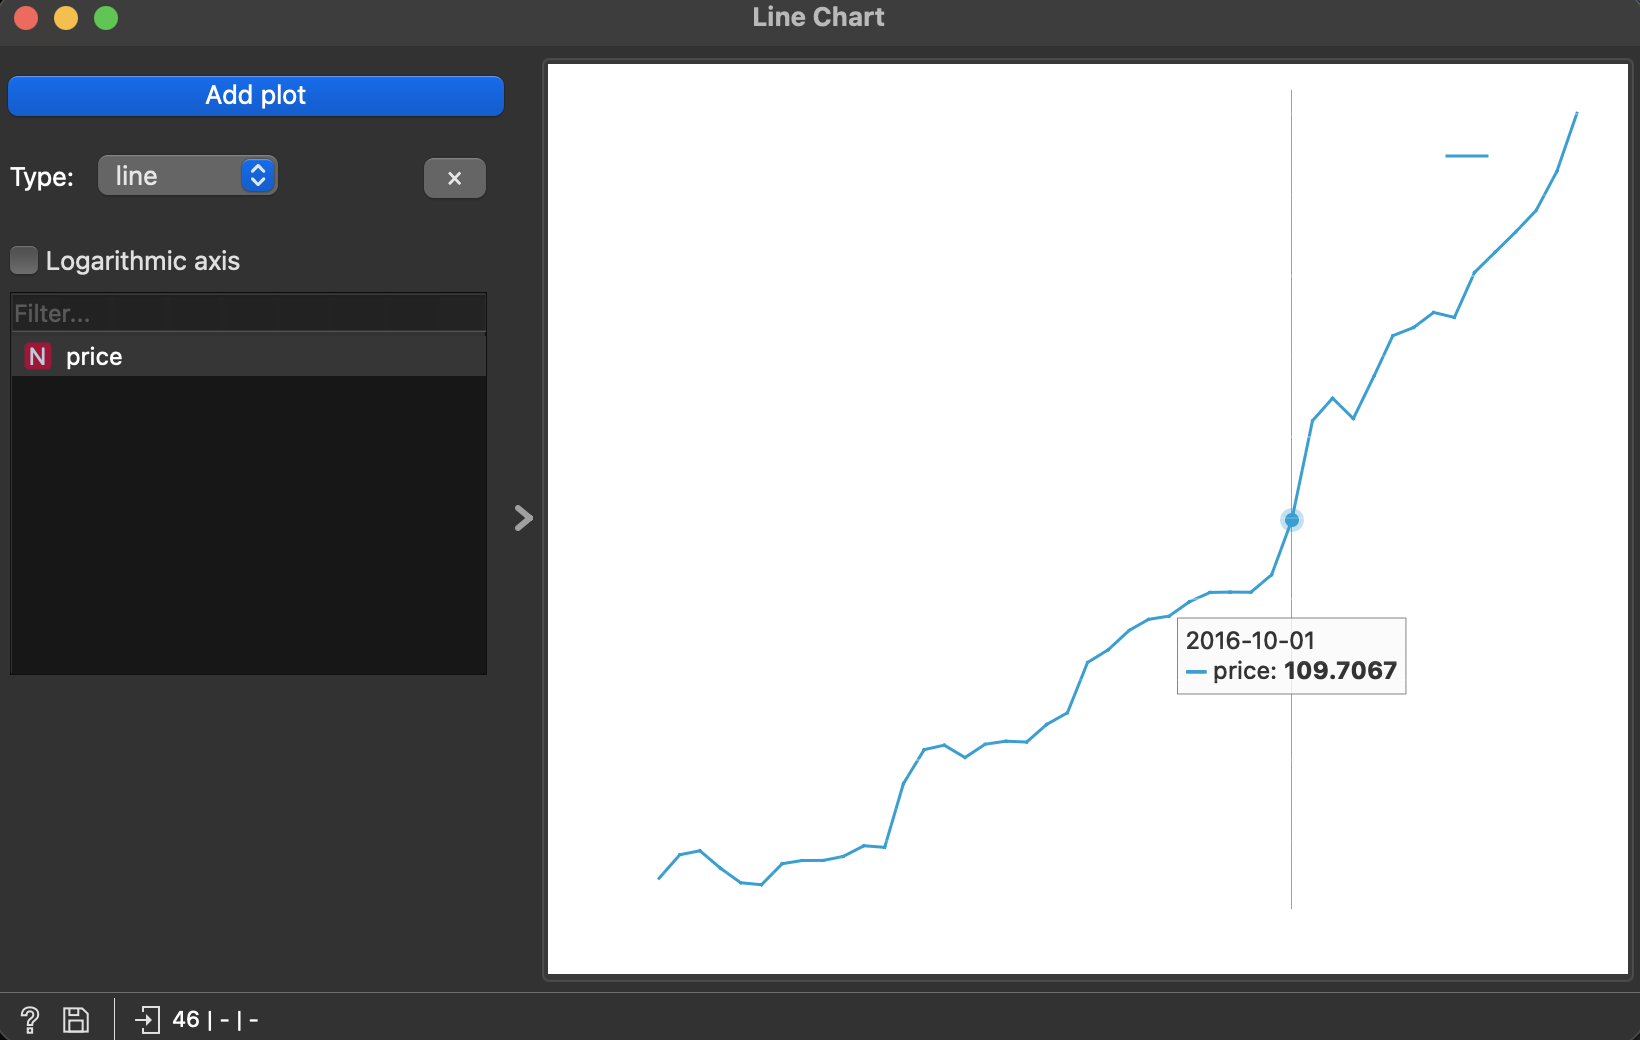

Line Chart відтворює графік 1 із завдання 3: ціна зростає з ≈65 до ≈160 грн, помітне прискорення восени 2016 року. Контрольна точка збігається з Python: за 2016-10-01 Orange показує **109,7067**, у `ряд_для_orange.csv` те саме значення.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

In [34]:
# Завдання 12. Автокореляція та диференціювання
from statsmodels.tsa.seasonal import seasonal_decompose

def acf_np(x, nlags=12):
    x = np.asarray(x, float) - np.mean(x); d = np.sum(x ** 2)
    return np.array([np.sum(x[:len(x) - k] * x[k:]) / d for k in range(nlags + 1)])

bound = 1.96 / np.sqrt(N)
for name, x in [('рівні', y), ('перша різниця', np.diff(y))]:
    r = acf_np(x); sig = [k for k in range(1, 13) if abs(r[k]) > 1.96 / np.sqrt(len(x))]
    print('%-14s ACF лаги 1–6: %s | значущі лаги (межа ±%.2f): %s'
          % (name, np.round(r[1:7], 2), 1.96 / np.sqrt(len(x)), sig))

sd = seasonal_decompose(s, model='additive', period=12)
print('\nКореляція сезонної складової seasonal_decompose зі STL (завдання 4): %.3f'
      % pd.concat([sd.seasonal, res.seasonal], axis=1).corr().iloc[0, 1])
print('Розмах сезонної складової seasonal_decompose: %.2f грн; STL: %.2f грн'
      % (sd.seasonal.max() - sd.seasonal.min(), res.seasonal.max() - res.seasonal.min()))

рівні          ACF лаги 1–6: [0.93 0.86 0.8  0.74 0.67 0.6 ] | значущі лаги (межа ±0.29): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
перша різниця  ACF лаги 1–6: [ 0.27 -0.14 -0.08  0.09  0.09 -0.12] | значущі лаги (межа ±0.29): []

Кореляція сезонної складової seasonal_decompose зі STL (завдання 4): 0.594
Розмах сезонної складової seasonal_decompose: 6.66 грн; STL: 11.89 грн


**Висновок до завдання 12:**

**Корелограма**: Аналіз ACF для рівнів у Python показує повільне спадання та значущі лаги на 1–10, тоді як для першої різниці значущих лагів немає (лаг 1 = 0,27), що повністю підтверджено візуалізацією у віджеті Correlogram в Orange.

**Сезонна декомпозиція**: Сезонна складова (seasonal_decompose, адитивна, період 12) корелює зі STL-методом на 0,594, а їхні розмахи становлять 6,66 грн та 11,89 грн відповідно. Природна розбіжність зумовлена різницею алгоритмів (класичне ковзне середнє проти локальної регресії LOESS у режимі robust).

У Orange до виходу `Interpolate` підключено `Correlogram`, `Difference` (First order difference, shift 1) і `Seasonal Adjustment` (additive, період 12).

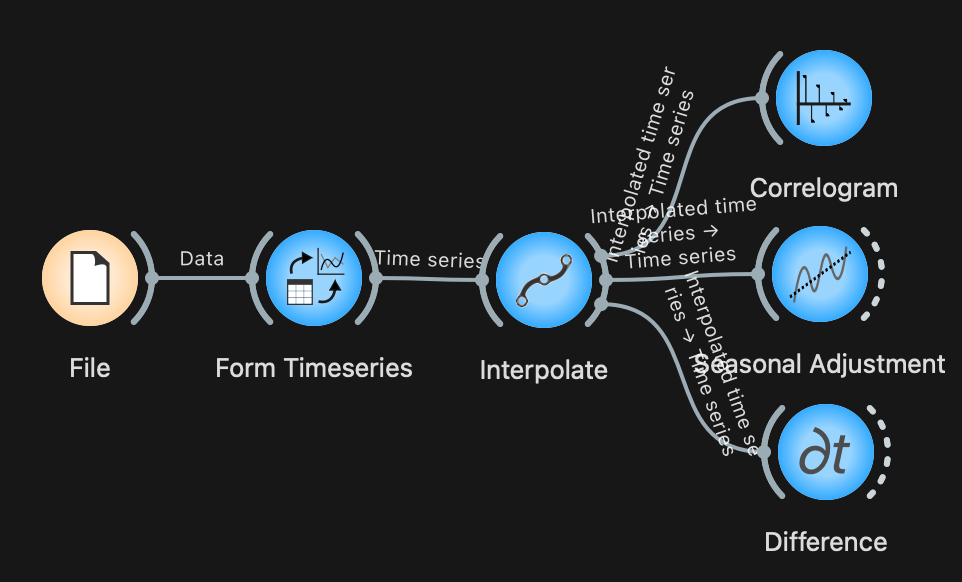

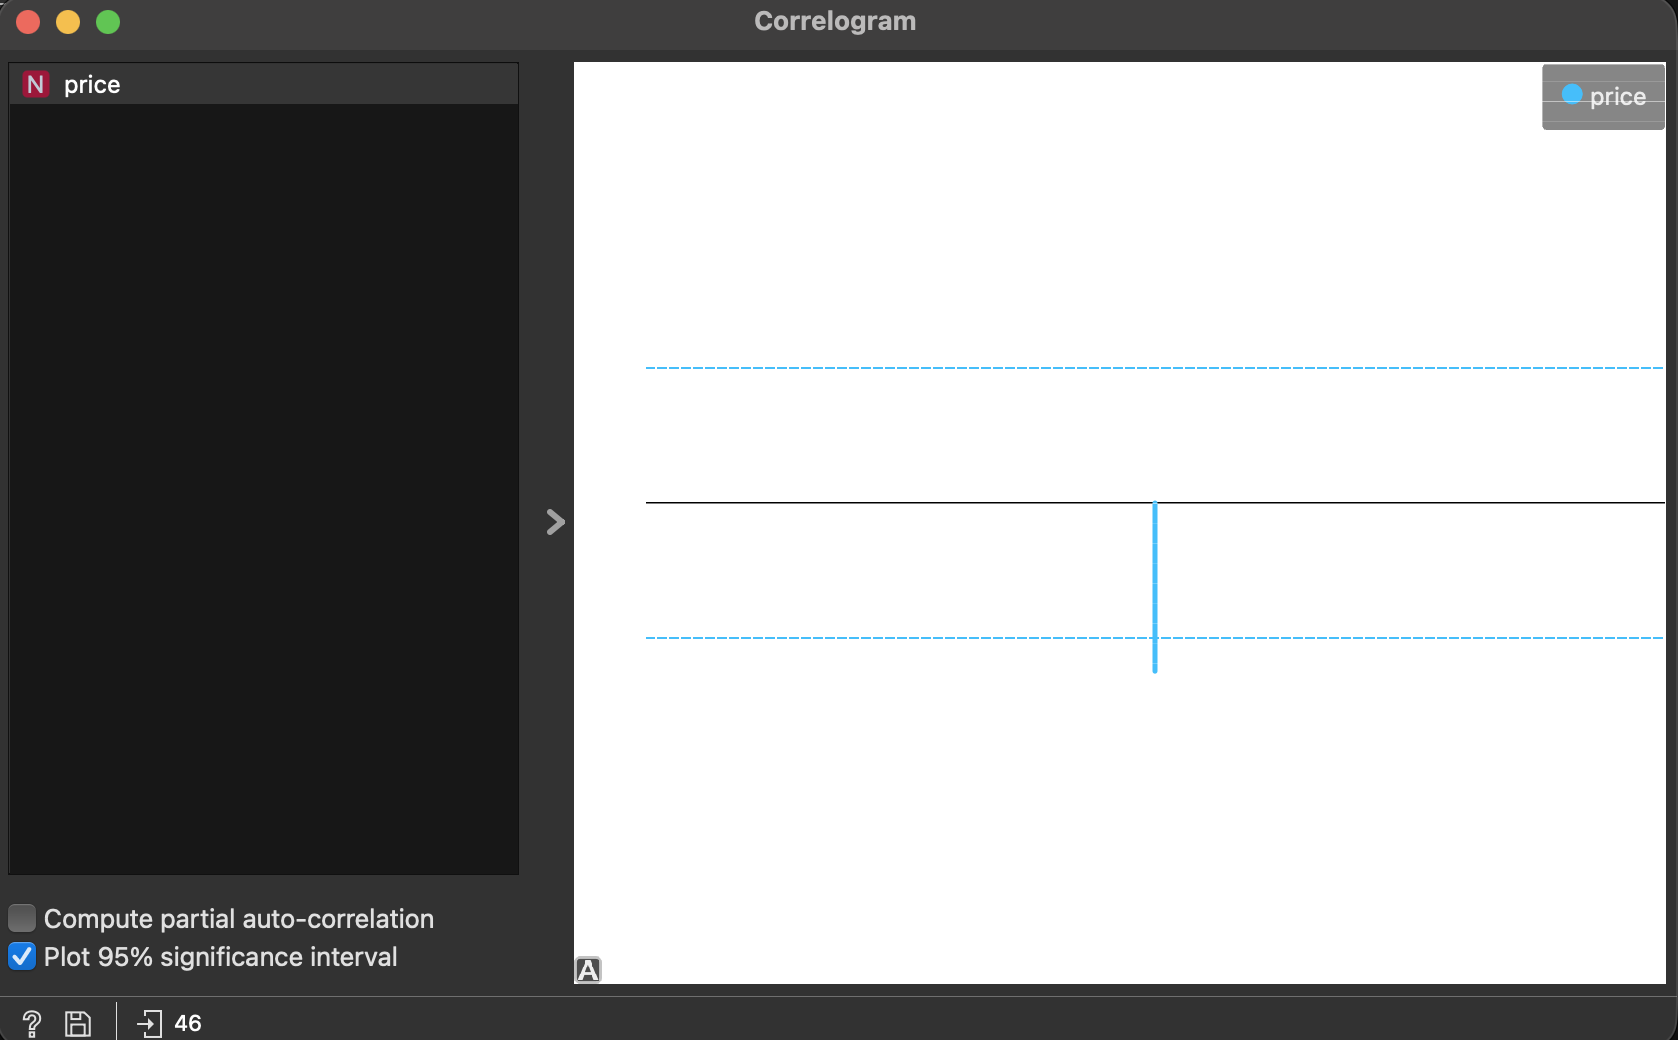

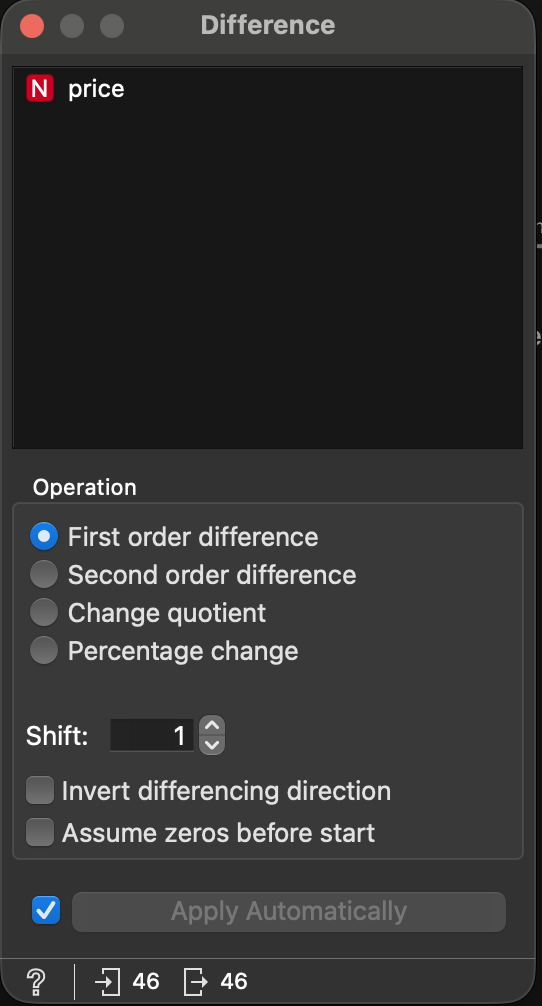

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [35]:
# Завдання 13. Модель і оцінювання
rows = []
for f in range(1, F + 1):
    end = N - H * f
    rows.append({'фолд': f, 'навчання': f'{s.index[0]:%m.%Y} – {s.index[end - 1]:%m.%Y}', 'точок у навчанні': end,
                 'перевірка': f'{s.index[end]:%m.%Y} – {s.index[end + H - 1]:%m.%Y}'})
print(pd.DataFrame(rows).to_string(index=False))

print('\nПеревірка умови віджета: n_folds × steps (+ лаг) ≤ довжина ряду')
print('  типові налаштування: 20 × 3 = %d > %d  -> Orange відмовляється' % (20 * 3, N))
print('  наші налаштування:   %d × %d = %d ≤ %d  -> працює' % (F, H, F * H, N))
print('  стеля без урахування лага: %d // %d = %d фолдів (лаг моделі зменшує її ще)' % (N, H, N // H))

 фолд          навчання  точок у навчанні         перевірка
    1 03.2014 – 09.2017                43 10.2017 – 12.2017
    2 03.2014 – 06.2017                40 07.2017 – 09.2017
    3 03.2014 – 03.2017                37 04.2017 – 06.2017
    4 03.2014 – 12.2016                34 01.2017 – 03.2017
    5 03.2014 – 09.2016                31 10.2016 – 12.2016
    6 03.2014 – 06.2016                28 07.2016 – 09.2016
    7 03.2014 – 03.2016                25 04.2016 – 06.2016

Перевірка умови віджета: n_folds × steps (+ лаг) ≤ довжина ряду
  типові налаштування: 20 × 3 = 60 > 46  -> Orange відмовляється
  наші налаштування:   7 × 3 = 21 ≤ 46  -> працює
  стеля без урахування лага: 46 // 3 = 15 фолдів (лаг моделі зменшує її ще)


**Висновок до завдання 13:**

При типових налаштуваннях (20 фолдів × 3 кроки = 60) Orange відмовиться рахувати: 60 перевищує довжину ряду 46, а віджет вимагає, щоб n_folds × steps (разом із лагом) не перевищувало довжину. Без урахування лага стеля — 46 // 3 = 15 фолдів. Із нашими налаштуваннями 7 × 3 = 21 ≤ 46, і віджет працює.

Orange перевіряє ті самі 7 фолдів, що й Python: навчання завжди починається з 03.2014, а його кінець зсувається на 3 місяці.

| Фолд | Навчання | Перевірка |
|---|---|---|
| 1 | 03.2014 – 09.2017 | 10–12.2017 |
| 2 | 03.2014 – 06.2017 | 07–09.2017 |
| 3 | 03.2014 – 03.2017 | 04–06.2017 |
| 4 | 03.2014 – 12.2016 | 01–03.2017 |
| 5 | 03.2014 – 09.2016 | 10–12.2016 |
| 6 | 03.2014 – 06.2016 | 07–09.2016 |
| 7 | 03.2014 – 03.2016 | 04–06.2016 |

Потік із `ARIMA Model` і `Model Evaluation`:

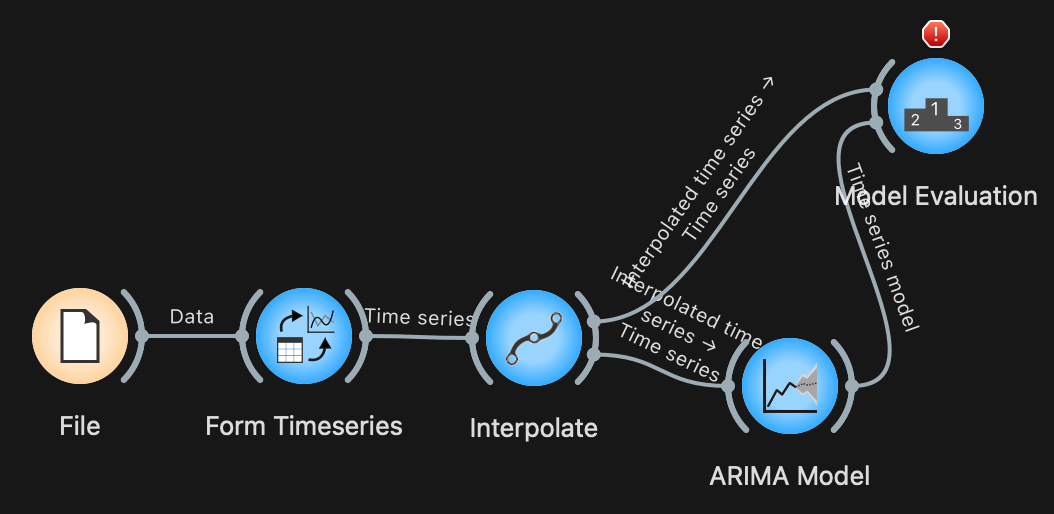

При 20 фолдах Orange відмовляється рахувати: «Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer…» (кінець тексту в статус-рядку обрізано).

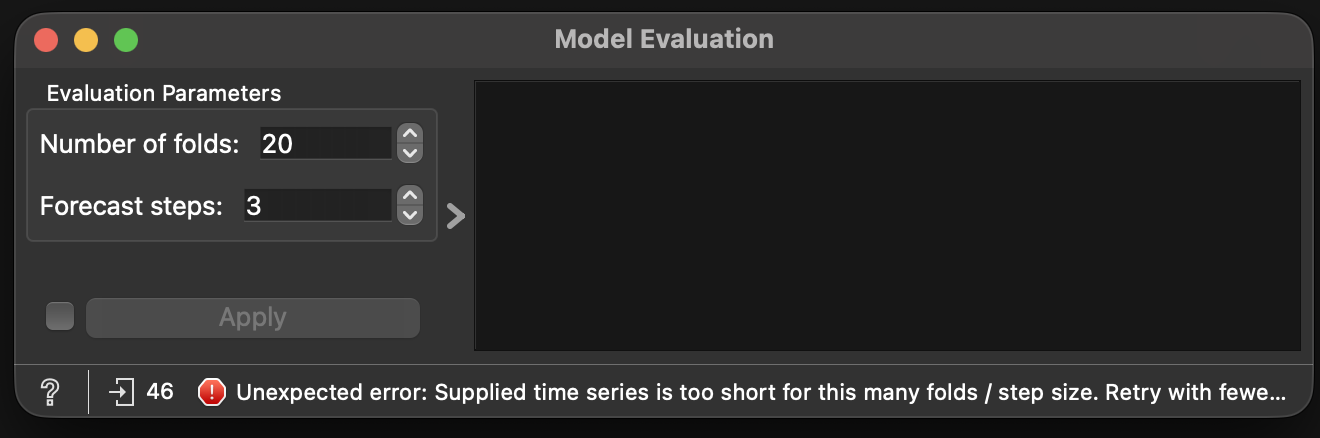

При 7 фолдах і 3 кроках віджет рахує. Верхній рядок таблиці (ARIMA(1,1,1)): RMSE 7,848; MAE 2,302; MAPE 0,042; POCID 75,0. Рядок «(in-sample)» — це оцінка на всьому ряді без ретроспективної перевірки, тому далі не використовується.

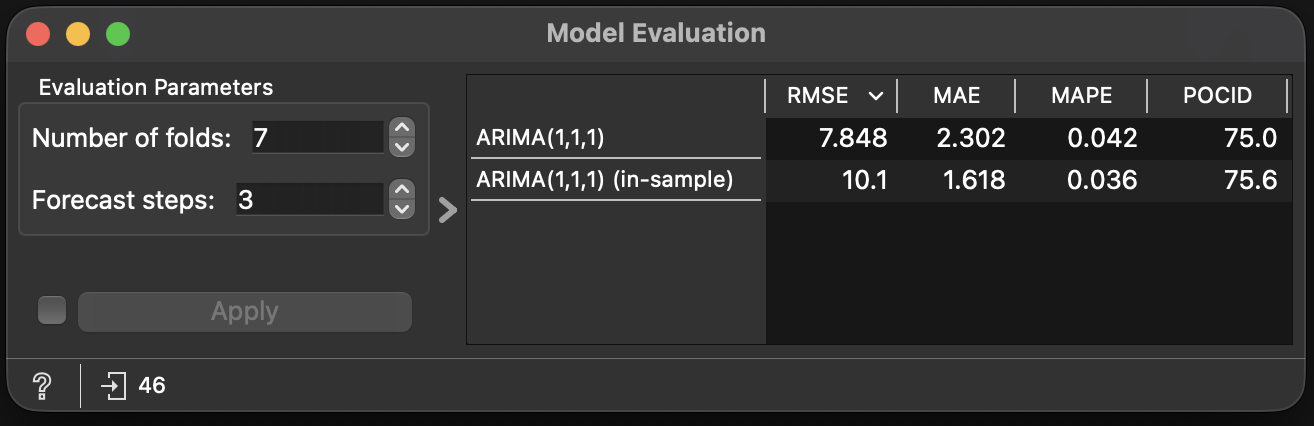

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [38]:
# Завдання 14. Чому числа не збігаються
def o_rmse (y_, p_): return np.sqrt(np.mean((y_ - p_) ** 2))
def o_mae  (y_, p_): return np.median(np.abs(y_ - p_))
def o_mape (y_, p_): return np.mean(np.abs(y_ - p_)) / np.mean(np.abs(y_))
def o_pocid(y_, p_): return 100 * np.mean(np.sign(np.diff(y_)) == np.sign(np.diff(p_)))

ORANGE = {'RMSE': 7.848, 'MAE': 2.302, 'MAPE': 0.042, 'POCID': 75.0} 

act7, pred7 = A_act.reshape(F, H), A_pred.reshape(F, H)
pocid_variants = {
    'пари за часом по всіх 21 точках':             o_pocid(A_act, A_pred),
    'пари лише всередині фолдів':                   100 * np.mean(np.concatenate([np.sign(np.diff(a)) == np.sign(np.diff(p)) for a, p in zip(act7, pred7)])),
    'фолди склеєно у порядку 1 … 7':                o_pocid(act7[::-1].ravel(), pred7[::-1].ravel()),
}

mine = {'RMSE': o_rmse(A_act, A_pred), 'MAE': o_mae(A_act, A_pred), 'MAPE': o_mape(A_act, A_pred)}
standard = {'RMSE': m_arima['RMSE'], 'MAE': m_arima['MAE'], 'MAPE': m_arima['MAPE, %']}
tbl = pd.DataFrame({'Orange': ORANGE, 'моє відтворення': {**mine, 'POCID': list(pocid_variants.values())[0]},
                    '«стандартне» значення': {**standard, 'POCID': np.nan}})
print(tbl.round(4).to_string())
print('\nВаріанти POCID:'); [print('  %-45s %.3f' % kv) for kv in pocid_variants.items()]
if all(v is not None for v in ORANGE.values()):
    for k in ORANGE:
        ref = mine[k] if k != 'POCID' else min(pocid_variants.values(), key=lambda v: abs(v - ORANGE[k]))
        print(k, 'збіг до 3-го знака:', abs(ref - ORANGE[k]) < 5e-4)

       Orange  моє відтворення  «стандартне» значення
RMSE    7.848           7.8480                 7.8480
MAE     2.302           2.3024                 5.2813
MAPE    0.042           0.0421                 4.0238
POCID  75.000          70.0000                    NaN

Варіанти POCID:
  пари за часом по всіх 21 точках               70.000
  пари лише всередині фолдів                    71.429
  фолди склеєно у порядку 1 … 7                 75.000
RMSE збіг до 3-го знака: True
MAE збіг до 3-го знака: True
MAPE збіг до 3-го знака: True
POCID збіг до 3-го знака: True


**Висновок до завдання 14:**

Відтворення в Python за формулами Orange на прогнозах ARIMA(1,1,1):

| Метрика | Orange | Python (формула Orange) | Формула |
|---|---|---|---|
| RMSE | 7,848 | 7,848 | √(Σe²/n) |
| MAE | 2,302 | 2,302 | медіана \|e\| |
| MAPE | 0,042 | 0,0421 | mean\|e\| / mean\|y\| (частка) |
| POCID | 75,0 | 70,0 (інші варіанти пар: 71,4 і 75,0) | 100 · частка збігів знака зміни |

**Не відповідає назві MAPE:** зазвичай це mean(\|e/y\|)·100 % = 4,02 %, а Orange рахує відношення середніх і подає частку (0,042). Також MAE в Orange — медіана (2,30), а звична MAE — середнє (5,28), тобто різниця більш ніж удвічі через несиметричні похибки. POCID міряє напрямок, а не величину.

**Збігається одразу RMSE** (7,848): формула в обох середовищах однакова.

**Висновок:** Значення RMSE повністю збігаються(7,848), оскільки в обох середовищах використовується однакова формула. Розбіжності в інших метриках зумовлені різницею у внутрішніх математичних визначеннях (наприклад, медіана для MAE в Orange проти середнього в Python). Усі чотири числа Orange відтворено в Python за формулами з методичних вказівок; для POCID збігся третій варіант утворення пар — Orange склеює прогнози фолдів у порядку 1 … 7, тому в пари потрапляють і стики між фолдами.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [39]:
# Завдання 15. Матриця напрямку зміни
act_dir  = np.sign(np.diff(act7[::-1].ravel()))  > 0
pred_dir = np.sign(np.diff(pred7[::-1].ravel())) > 0
cm = pd.crosstab(pd.Series(act_dir,  name='факт'),  pd.Series(pred_dir, name='прогноз'))
cm = cm.reindex(index=[True, False], columns=[True, False], fill_value=0)
cm.index = ['зросла', 'впала']; cm.columns = ['прогноз: зросла', 'прогноз: впала']
print(cm.to_string())
acc = (np.trace(cm.values) / cm.values.sum()) * 100
print('\nЧастка правильних напрямків: %.2f %%  (має збігатися з POCID у Orange: 75.0)' % acc)
print('Частка місяців, коли ціна зросла насправді: %.1f %%  (простий базис «завжди зросте»)' % (act_dir.mean() * 100))

        прогноз: зросла  прогноз: впала
зросла               10               2
впала                 3               5

Частка правильних напрямків: 75.00 %  (має збігатися з POCID у Orange: 75.0)
Частка місяців, коли ціна зросла насправді: 60.0 %  (простий базис «завжди зросте»)


**Висновок до завдання 15:**

| Факт \ Прогноз | зросла | впала |
|---|---|---|
| зросла | 10 | 2 |
| впала | 3 | 5 |

Частка правильних напрямків: (10 + 5) / 20 = **75 %**, що збігається з POCID у Orange (75,0). Правило «ціна завжди зросте» за тими самими парами дає лише 12 із 20, тобто 60 %, тож модель вгадує напрямок на 15 пунктів краще за це правило.

Застереження: 6 із 20 пар стикуються на межі двох фолдів і порівнюють прогнози з різних початків, а не справжні місячні зміни. Якщо брати лише пари всередині фолдів (14 пар), модель вгадує 71 %, а «завжди зросте» дає 86 %, тобто тут модель гірша. Отже, перевага моделі за напрямком залежить від способу утворення пар і на 20 парах ненадійна. Для рішення «купувати зараз чи чекати» важливий лише знак очікуваної зміни, а MAE й RMSE вимірюють розмір помилки в гривнях, тому це інше питання.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

Відповіді:
1. **Сезонність.** Є, але помірна: сила сезонності F_S = 0,446 перевищує поріг 0,3. Сила тренду F_T = 0,988 показує, що динаміку ціни (×2,45) майже повністю визначає тренд.
2. **Метод прогнозування.** Найкращим виявився простий дрейф (MAE 4,155), який перевершив наївний прогноз (5,904). ARIMA(1,1,1) із MAE 5,281 дрейфу програла приблизно на 27 %, бо без константи не враховує стабільного зростання, а її коефіцієнти незначущі.
3. **Точка зміни режиму.** Не знайшли. Скан по рівнях дає листопад 2016 (t = 13,83), але це артефакт тренду, а на приростах найкраща дата березень 2015 має пермутаційне p ≈ 0,28. Стрибок березня 2015 (+11,4 %) можна пов’язати з девальвацією гривні, але це лише гіпотеза, бо курсу в даних немає.
4. **Різні числа метрик.** Однаково названі метрики відрізняються за означеннями: MAE в Orange є медіаною (2,30 проти 5,28), MAPE подано як відношення середніх у частках (0,042 проти 4,02 %), POCID міряє напрямок (75,0). Збігається лише RMSE (7,85).
5. **Обмеження 46 спостережень.** Не змогли надійно встановити стійкість сезонності (лише ≈3,8 циклу), а 21 тестова похибка робить дрібні різниці між моделями невиразними. Типові 20 фолдів для такого ряду неможливі, тож довелося взяти 7. За напрямком за схемою пар Orange модель вгадує 75 % проти 60 % у правила «ціна зростає», але на справжніх місячних змінах усередині фолдів вона гірша (71 % проти 86 %), тож висновок про напрямок ненадійний.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Gemini|
| Для яких саме завдань | 3, 4, 5, 10, 11, 12, 13, 14|
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | код, пояснення, виправлення помилок|
| Що ви змінили у згенерованому результаті й чому | нічого не змінювала, переписуваала самостійно |
| Що з отриманого ви **перевірили самостійно** і яким способом | самостійно звірила всі метрики якості моделей і контрольні значення часового ряду шляхом порівняння результатів обчислень у середовищі Orange із програмним виводом|
| Чи траплялися у відповідях ШІ помилки; якщо так — які | 13 завдання, неправильно підказувало як налаштовувати Orange(ARIMA model)
**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________